In [0]:
print("\n" + "=" * 70)
print("ITERATION 2: Same features + StandardScaler + KMeans")
print("=" * 70)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import PowerTransformer # changed
from sklearn.metrics import silhouette_score, silhouette_samples

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)


ITERATION 2: Same features + StandardScaler + KMeans


In [0]:
# ------------------------------------------------------------
# 0) Load Spotify Tables (Spark → Pandas)
# ------------------------------------------------------------
spotify_user_behavior = spark.table("workspace.spotify.spotify_user_behavior").toPandas()
spotify_user_demo     = spark.table("workspace.spotify.spotify_user_demo").toPandas()

In [0]:
# ------------------------------------------------------------
# 4) Manual Feature Selection (Core Behavioral Axes)
# ------------------------------------------------------------

# WHY ONLY 7 FEATURES?
# - Represent distinct behavioral dimensions
# - Avoid correlated / redundant metrics
# - Keep persona interpretation simple

CLUSTER_FEATURES_V1 = [
    "daily_listening_minutes",     # usage intensity
    "sessions_per_day",            # frequency
    "days_active_last_30",         # consistency
    "avg_session_minutes",         # depth
    "skip_rate",                   # content friction
    "liked_songs_pct",             # positive engagement
    "ads_skipped_pct",             # monetization friction
]

In [0]:

# ------------------------------------------------------------
# 5) Column existence validation (manual, explicit)
# ------------------------------------------------------------

missing_1 = "daily_listening_minutes" not in spotify_user_behavior.columns
missing_2 = "sessions_per_day" not in spotify_user_behavior.columns
missing_3 = "days_active_last_30" not in spotify_user_behavior.columns
missing_4 = "avg_session_minutes" not in spotify_user_behavior.columns
missing_5 = "skip_rate" not in spotify_user_behavior.columns
missing_6 = "liked_songs_pct" not in spotify_user_behavior.columns
missing_7 = "ads_skipped_pct" not in spotify_user_behavior.columns

if missing_1 or missing_2 or missing_3 or missing_4 or missing_5 or missing_6 or missing_7:
    missing_cols = []
    if missing_1: missing_cols.append("daily_listening_minutes")
    if missing_2: missing_cols.append("sessions_per_day")
    if missing_3: missing_cols.append("days_active_last_30")
    if missing_4: missing_cols.append("avg_session_minutes")
    if missing_5: missing_cols.append("skip_rate")
    if missing_6: missing_cols.append("liked_songs_pct")
    if missing_7: missing_cols.append("ads_skipped_pct")

    raise ValueError(f"Missing required columns: {missing_cols}")

In [0]:
# ------------------------------------------------------------
# 6) Build modeling base table
# ------------------------------------------------------------

base = spotify_user_behavior[
    ["user_id"] + CLUSTER_FEATURES_V1
].copy()

# .copy() is CRITICAL:
# - prevents chained assignment issues
# - avoids modifying original dataframe

In [0]:
print("\nNull check (selected features):")
print(base[CLUSTER_FEATURES_V1].isnull().sum())


Null check (selected features):
daily_listening_minutes    0
sessions_per_day           0
days_active_last_30        0
avg_session_minutes        0
skip_rate                  0
liked_songs_pct            0
ads_skipped_pct            0
dtype: int64


In [0]:
# ------------------------------------------------------------
# 8) Range sanity checks (percentage features)
# ------------------------------------------------------------

print("\nRange checks (pct features):")

print(f"{'skip_rate':16s} min={base['skip_rate'].min():.4f}  max={base['skip_rate'].max():.4f}")
print(f"{'liked_songs_pct':16s} min={base['liked_songs_pct'].min():.4f}  max={base['liked_songs_pct'].max():.4f}")
print(f"{'ads_skipped_pct':16s} min={base['ads_skipped_pct'].min():.4f}  max={base['ads_skipped_pct'].max():.4f}")

# Expected range: [0, 1]
# Out-of-range values indicate ETL issues


Range checks (pct features):
skip_rate        min=0.0006  max=1.0000
liked_songs_pct  min=0.0003  max=0.9737
ads_skipped_pct  min=0.0120  max=1.0000


In [0]:
# ------------------------------------------------------------
# 9) Drop rows with missing values (HOL simplification)
# ------------------------------------------------------------

before_rows = len(base)
base = base.dropna(subset=CLUSTER_FEATURES_V1)
after_rows = len(base)

if before_rows != after_rows:
    print(f"Dropped {before_rows - after_rows} rows due to nulls")

In [0]:
# ------------------------------------------------------------
# 10) Set number of clusters
# ------------------------------------------------------------

K = 4
# 3–4 clusters are interpretable for business personas

# ------------------------------------------------------------
# 11) Build feature matrix X (UNSCALED)
# ------------------------------------------------------------

X1 = base[CLUSTER_FEATURES_V1].copy()

In [0]:
pt=PowerTransformer(
    method="yeo-johnson",
)
#default is yeo-johnson
#works with zero / negative values safely (more robust for real_world)
#alternative box cox
standardize=True

In [0]:
#step 2 :fit scalar on x1 and transform x1 in one step 
X2_scaled = pt.fit_transform(X1)

# fit_transform() does TWO things:
# 1) fit(): learns mean and std for each column in X1
# 2) transform(): applies z-score scaling using those learned params
#
# NOTE:
# - Always fit scaler ONLY on training data in production
# - In HOL, we fit on full dataset for simplicity

In [0]:
# ------------------------------------------------------------
# Step 3: Convert scaled array back to DataFrame (so column names remain)
# ------------------------------------------------------------
X2 = pd.DataFrame(
    X2_scaled,
    columns=CLUSTER_FEATURES_V1,
    index=base.index
)

# WHY convert back to DataFrame?
# - Keeps column names for debugging/inspection
# - Keeps index aligned with base/base_iter tables
# - Makes silhouette plotting and any later joins easier

In [0]:
#9) fit gmm
gmm8= GaussianMixture(
    n_components=K,
    covariance_type="full",
    random_state=42,
    n_init=5,
    max_iter=200
)
labels8=gmm8.fit_predict(X2)
log_likelihood=gmm8.score(X2)*len(X2)

In [0]:
# ------------------------------------------------------------
# Step 4: Fit KMeans on SCALED space (manual, no helper function)
# ------------------------------------------------------------
# km2 = KMeans(
#     n_clusters=K,
#     random_state=42,   # ensures same initialization behavior across runs
#     n_init=20,         # more stable than sklearn default (often 10)
#     max_iter=300       # sklearn default
# )

labels2 = gmm8.fit_predict(X2)

# fit_predict():
# - Fits centroids in scaled feature space
# - Assigns each row to nearest centroid based on Euclidean distance

# inertia2 = gmm8.inertia_
log_likelihood=gmm8.score(X2)*len(X2)

# inertia meaning reminder:
# - Sum of squared distances to closest centroid
# - In scaled space, inertia becomes more comparable feature-to-feature
# - Still not a "quality" metric alone (silhouette is better)

In [0]:
# ------------------------------------------------------------
# Step 5: Compute silhouette score in SCALED space (correct)
# ------------------------------------------------------------
# Silhouette MUST be computed in the same space used for clustering
sil_avg_2 = silhouette_score(X2, labels2)

# silhouette range [-1, 1]
# Higher = better separation

In [0]:
# ------------------------------------------------------------
# Step 6: Attach labels to ORIGINAL base table
# ------------------------------------------------------------
base_iter2 = base.copy()
base_iter2["cluster"] = labels2

# IMPORTANT:
# - base_iter2 still has original raw values
# - labels were produced using scaled geometry
# - this is the best practice:
#     fit in scaled space, interpret in original space

print(f"\nIteration 2 results | k={K}")
# print("Inertia   :", round(inertia2, 2))
print("log likelihood",round(log_likelihood,2))
print("Silhouette:", round(sil_avg_2, 3))


Iteration 2 results | k=4
log likelihood 47034.04
Silhouette: 0.114


In [0]:
# ------------------------------------------------------------
# Step 7: Cluster profile (means) — ORIGINAL units
# ------------------------------------------------------------
sizes2 = base_iter2["cluster"].value_counts().sort_index()

means2 = (
    base_iter2
    .groupby("cluster")[CLUSTER_FEATURES_V1]
    .mean()
    .round(3)
)

profile2 = means2.copy()
profile2.insert(0, "cluster_size", sizes2)

print("\nCluster profile (means, original scale) — Iteration 2 (StandardScaler labels):")
display(profile2)


Cluster profile (means, original scale) — Iteration 2 (StandardScaler labels):


cluster_size,daily_listening_minutes,sessions_per_day,days_active_last_30,avg_session_minutes,skip_rate,liked_songs_pct,ads_skipped_pct
25773,65.27342687603547,1.0,21.753816812581487,65.27342687603547,0.288,0.3019945361430282,0.5839138415642019
27544,12.85192890075303,1.0,20.59578049211053,12.85192890075303,0.383,0.2620442369633464,0.506244936813634
20403,77.68456173943838,2.63,21.714096469795834,29.20287803362299,0.305,0.29823237098076677,0.5673281092669187
34280,26.892410243702038,1.0,20.87410338994352,26.892410243702038,0.32,0.2865595189213723,0.5298294260373992


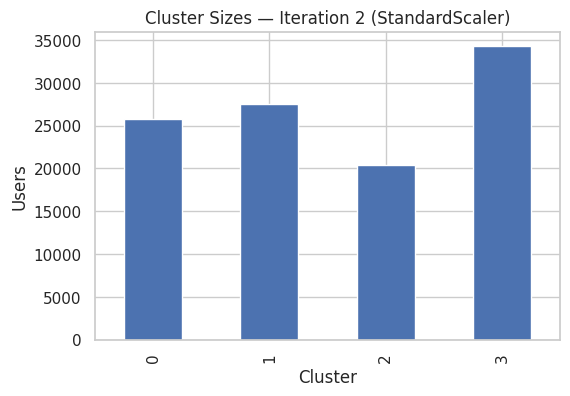

In [0]:
# ------------------------------------------------------------
# Step 8: Cluster sizes bar chart
# ------------------------------------------------------------
plt.figure(figsize=(6, 4))
base_iter2["cluster"].value_counts().sort_index().plot(kind="bar")
plt.title("Cluster Sizes — Iteration 2 (StandardScaler)")
plt.xlabel("Cluster")
plt.ylabel("Users")
plt.show()

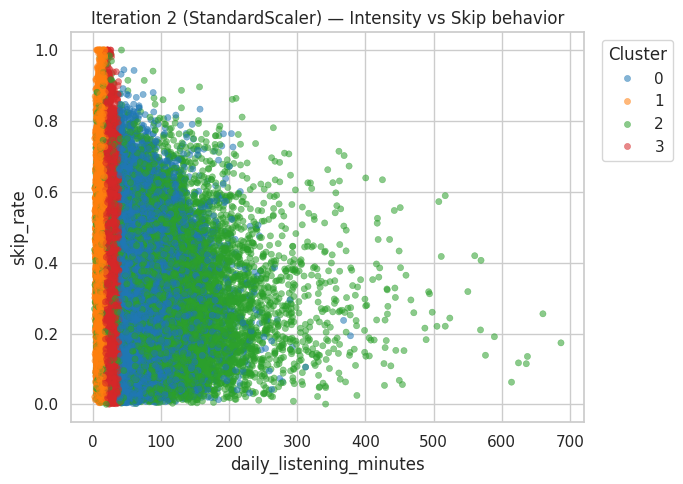

In [0]:
# ------------------------------------------------------------
# Step 9: Scatter plots (NO PCA) — manual (no loop)
# NOTE:
# - Axes are ORIGINAL units (interpretable)
# - Colors (labels) come from SCALED clustering
# ------------------------------------------------------------

# Plot 1: Intensity vs Skip behavior
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=base_iter2,
    x="daily_listening_minutes",
    y="skip_rate",
    hue="cluster",
    palette="tab10",
    s=20,
    alpha=0.55,
    edgecolor=None
)
plt.title("Iteration 2 (StandardScaler) — Intensity vs Skip behavior")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()




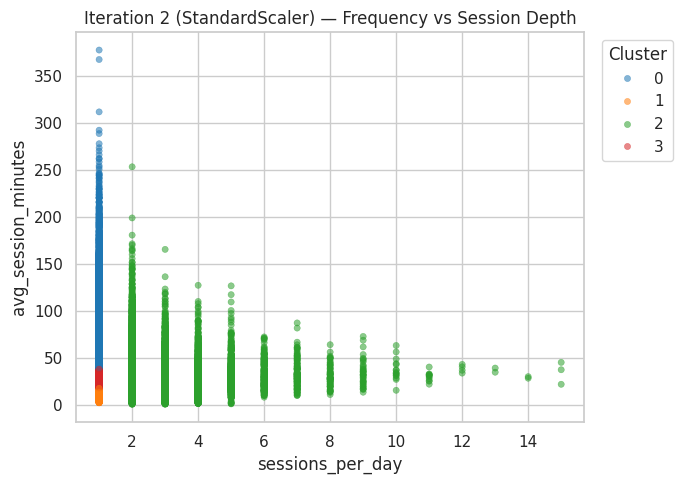

In [0]:
# Plot 2: Frequency vs Session Depth
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=base_iter2,
    x="sessions_per_day",
    y="avg_session_minutes",
    hue="cluster",
    palette="tab10",
    s=20,
    alpha=0.55,
    edgecolor=None
)
plt.title("Iteration 2 (StandardScaler) — Frequency vs Session Depth")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

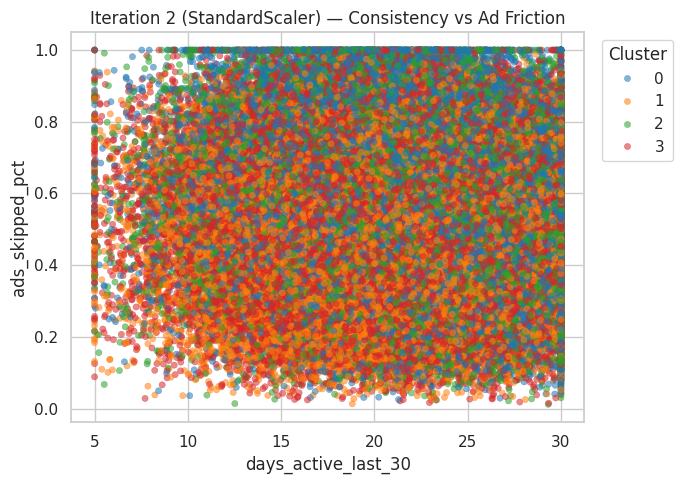

In [0]:

# Plot 3: Consistency vs Ad Friction
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=base_iter2,
    x="days_active_last_30",
    y="ads_skipped_pct",
    hue="cluster",
    palette="tab10",
    s=20,
    alpha=0.55,
    edgecolor=None
)
plt.title("Iteration 2 (StandardScaler) — Consistency vs Ad Friction")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

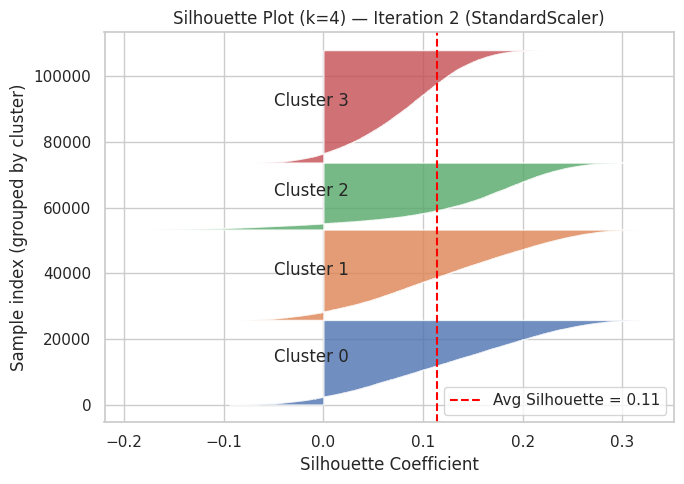

Iteration 2 Avg Silhouette: 0.114


In [0]:
# ------------------------------------------------------------
# Step 10: Silhouette Plot (Iteration 2) — MANUAL, NO LOOPS
# IMPORTANT:
# - silhouette is computed on X2 (scaled space), not on base_iter2
# ------------------------------------------------------------

sil_values_2 = silhouette_samples(X2, labels2)

plt.figure(figsize=(7, 5))
y_lower = 0

# ---- Cluster 0
vals0 = sil_values_2[labels2 == 0]
vals0.sort()
size0 = vals0.shape[0]
y_upper = y_lower + size0
plt.fill_betweenx(np.arange(y_lower, y_upper), 0, vals0, alpha=0.8)
plt.text(-0.05, y_lower + 0.5 * size0, "Cluster 0")
y_lower = y_upper

# ---- Cluster 1
vals1 = sil_values_2[labels2 == 1]
vals1.sort()
size1 = vals1.shape[0]
y_upper = y_lower + size1
plt.fill_betweenx(np.arange(y_lower, y_upper), 0, vals1, alpha=0.8)
plt.text(-0.05, y_lower + 0.5 * size1, "Cluster 1")
y_lower = y_upper

# ---- Cluster 2
vals2 = sil_values_2[labels2 == 2]
vals2.sort()
size2 = vals2.shape[0]
y_upper = y_lower + size2
plt.fill_betweenx(np.arange(y_lower, y_upper), 0, vals2, alpha=0.8)
plt.text(-0.05, y_lower + 0.5 * size2, "Cluster 2")
y_lower = y_upper

# ---- Cluster 3
vals3 = sil_values_2[labels2 == 3]
vals3.sort()
size3 = vals3.shape[0]
y_upper = y_lower + size3
plt.fill_betweenx(np.arange(y_lower, y_upper), 0, vals3, alpha=0.8)
plt.text(-0.05, y_lower + 0.5 * size3, "Cluster 3")
y_lower = y_upper

# Average silhouette reference line
plt.axvline(
    x=sil_avg_2,
    color="red",
    linestyle="--",
    label=f"Avg Silhouette = {sil_avg_2:.2f}"
)

plt.title("Silhouette Plot (k=4) — Iteration 2 (StandardScaler)")
plt.xlabel("Silhouette Coefficient")
plt.ylabel("Sample index (grouped by cluster)")
plt.legend()
plt.tight_layout()
plt.show()

print("Iteration 2 Avg Silhouette:", round(sil_avg_2, 3))